# Multi-follower Stackelberg experiment

Each entry in `scenarios`, `lower_nets`, and `mg_buses` describes the same follower. Every follower receives an independent 24-hour price trajectory when more than one follower is configured. Run the notebook from top to bottom in this order: neural-surrogate solver (NN), zero-order solver (CMA-ES), and residual-correction trust-region algorithm.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandapower.networks as pn
 
from stackelberg.followers.bg import create_cigre_residential_network
from stackelberg.followers.ip import create_industrial_park_network
from stackelberg.network import create_case33bw_20kv
from stackelberg.nn_solver import (
    NNSolverExperimentConfig,
    run_nn_solver_experiment,
)
from stackelberg.trust_region import (
    TrustRegionExperimentConfig,
    run_trust_region_experiment,
)
from stackelberg.zero_order import (
    ZeroOrderExperimentConfig,
    run_zero_order_experiment,
)

## Networks and follower mapping

The order is important: follower `i` uses `scenarios[i]`, `lower_nets[i]`, connects at `mg_buses[i]`, and loads `L2O_<follower_id>.pth`.

In [5]:
T = 24
upper_net = create_case33bw_20kv()

# The three lists use the same follower order.
scenarios = ["SB1", "SB2", "BG1", "BG2", "IP1",]
# SB uses pn.create_cigre_network_lv()
# BG uses create_cigre_residential_network()
lower_nets = [
    pn.create_cigre_network_lv(),
    pn.create_cigre_network_lv(),
    create_cigre_residential_network(),
    create_cigre_residential_network(),
    create_industrial_park_network(),
]
mg_buses = [17, 32, 15, 21, 1]

rng1 = np.random.default_rng(42)
rng2 = np.random.default_rng(1)
# Shared initial prices make the three methods directly comparable.
# x0 = np.full((len(scenarios), T), 0.75) # the center point 9.12
# x0 = np.full((len(scenarios), T), 0.0) # the lower bound  9.13
# x0 = np.full((len(scenarios), T), 1.5) # the upper bound 9.13
# x0 = rng1.random((len(scenarios), T)) * 1.5 # the random starting point 9.14
x0 = rng2.random((len(scenarios), T)) * 1.5 # the random starting point 9.14
x0

array([[0.76773244, 1.42569554, 0.21623942, 1.42297417, 0.46774718,
        0.63498967, 1.24155389, 0.6137987 , 0.82439053, 0.04133867,
        1.13026966, 0.80721497, 0.49459757, 1.18264306, 0.45479224,
        0.68024683, 0.20106255, 0.60466948, 0.30518286, 0.39347001,
        1.12554701, 0.42061314, 0.72778646, 1.4711058 ],
       [1.44248579, 1.08718491, 0.81184028, 0.41533681, 0.24097801,
        1.45488812, 0.77410288, 0.17379842, 0.93523463, 1.16502467,
        0.91950495, 1.37594656, 0.05938931, 0.79288389, 0.68900382,
        0.09352437, 0.96199225, 1.27894926, 0.88941153, 0.39014617,
        1.25982228, 0.76424382, 0.76633333, 1.12954531],
       [0.22188305, 1.22944008, 1.02493036, 1.18064541, 0.28742439,
        1.20354624, 0.28698589, 0.12232893, 1.28284046, 1.29192524,
        1.31480564, 0.70786458, 0.41107258, 0.01063774, 0.96858134,
        1.07986408, 1.25335382, 0.42281674, 0.32282725, 0.95899707,
        1.20758225, 1.44550631, 0.22578725, 0.72331858],
       [1.342

## 1. Neural-surrogate solver (NN) or saved warm start

Set `RUN_NN_SOLVER=True` to run and save a new NN solution. Leave it `False` to read the last recorded price vector from the newest `results/NN_solver_history_*.csv` without rerunning the solver.

In [6]:
RUN_NN_SOLVER = True

nn_config = NNSolverExperimentConfig(
    upper_net=upper_net,
    lower_nets=lower_nets,
    mg_buses=mg_buses,
    scenarios=scenarios,
    T=T,
    seed=42,
    device="cpu",
    x0=x0,
    steps=10000,
    lr=1e-2,
    save_every=200,
    history_path="results/NN_solver_history.csv",
    evaluate_true=True,
    save_results=True,
)

if RUN_NN_SOLVER:
    nn_result = run_nn_solver_experiment(nn_config)
    nn_prices = np.asarray(nn_result["optimal pi"]).reshape(len(scenarios), T)
    warm_start_point = nn_prices.copy()
    print("Ran NN solver and saved history to:", nn_result.get("history_path"))
else:
    results_dir = Path("results")
    history_candidates = list(results_dir.glob("NN_solver_history_*.csv"))
    if not history_candidates:
        fallback_history = results_dir / "NN_solver_history.csv"
        if fallback_history.is_file():
            history_candidates = [fallback_history]
    if not history_candidates:
        raise FileNotFoundError(
            "No NN solver history found in results/. Expected NN_solver_history_*.csv."
        )

    latest_nn_history_path = max(
        history_candidates,
        key=lambda path: path.stat().st_mtime_ns,
    )
    nn_history = pd.read_csv(latest_nn_history_path)
    if nn_history.empty:
        raise ValueError(f"NN solver history is empty: {latest_nn_history_path}")

    pi_columns = sorted(
        (column for column in nn_history.columns if column.startswith("pi_")),
        key=lambda column: int(column.removeprefix("pi_")),
    )
    expected_price_count = len(scenarios) * T
    if len(pi_columns) != expected_price_count:
        raise ValueError(
            f"Expected {expected_price_count} price columns, found {len(pi_columns)} "
            f"in {latest_nn_history_path}."
        )

    last_nn_row = nn_history.sort_values("iteration").iloc[-1]
    nn_prices = last_nn_row[pi_columns].to_numpy(dtype=float).reshape(
        len(scenarios), T
    )
    warm_start_point = nn_prices.copy()
    nn_result = {
        "optimal pi": nn_prices,
        "true_obj": float(last_nn_row["true_loss"])
        if "true_loss" in last_nn_row.index
        else np.nan,
        "runtime_seconds": np.nan,
        "history_path": str(latest_nn_history_path),
    }
    print("Loaded NN warm start from:", latest_nn_history_path)
    print("Saved iteration:", int(last_nn_row["iteration"]))

print("NN true objective:", nn_result["true_obj"])
print("Runtime seconds:", nn_result["runtime_seconds"])
display(pd.DataFrame(nn_prices, index=scenarios))

Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

[0] loss=8026.8354, obj=-86.2257, eq=8.1059, soc=0.0647, bound=0.0646, true_loss=37.8133
Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyr

,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
SB1,1.223752,1.480058,1.497777,1.163224,0.990416,1.432427,1.309361,1.000547,0.998128,1.010158,...,1.030130,1.032435,1.237040,1.499278,1.004961,1.497594,1.499878,0.991717,1.090643,1.374754
SB2,0.992457,1.498996,1.499549,0.993531,0.961779,0.950488,0.997009,1.005312,1.498973,1.499888,...,1.018065,1.498370,1.217062,1.499791,1.498604,1.499200,1.499963,1.344317,1.461623,1.195571
BG1,1.499922,1.499937,1.499882,1.499858,1.499925,1.499972,1.499930,1.499931,1.499974,1.499984,...,1.499946,1.499950,1.499979,1.499923,1.499922,1.499892,1.499979,1.499977,1.499928,1.499923
BG2,1.499842,1.499223,1.499523,1.499915,1.499724,1.499960,1.499968,1.499980,1.499842,1.499929,...,1.499982,1.499799,1.499893,1.499893,1.499951,1.499819,1.499705,1.499908,1.499923,1.499450
IP1,1.498728,1.494104,1.496890,1.498876,1.498614,1.444522,1.498829,1.499508,1.499664,1.499604,...,1.499597,1.499840,1.499613,1.499069,1.499135,1.499370,1.497011,1.497966,1.499368,1.497523


In [7]:
assert warm_start_point.shape == (len(scenarios), T)
warm_start_point

array([[1.2237518 , 1.4800581 , 1.4977775 , 1.1632242 , 0.99041617,
        1.4324269 , 1.3093612 , 1.0005468 , 0.99812806, 1.0101581 ,
        1.2499993 , 1.3073252 , 1.4540102 , 1.1913931 , 1.0301296 ,
        1.0324352 , 1.2370396 , 1.4992783 , 1.0049607 , 1.4975945 ,
        1.4998784 , 0.99171746, 1.0906434 , 1.3747536 ],
       [0.99245685, 1.4989963 , 1.499549  , 0.9935305 , 0.9617788 ,
        0.9504881 , 0.99700916, 1.0053122 , 1.4989733 , 1.4998882 ,
        1.3962789 , 1.4992801 , 1.0173662 , 0.96107244, 1.0180647 ,
        1.4983704 , 1.2170622 , 1.4997914 , 1.4986043 , 1.4991997 ,
        1.4999628 , 1.3443172 , 1.4616227 , 1.1955711 ],
       [1.4999223 , 1.4999367 , 1.4998816 , 1.499858  , 1.4999247 ,
        1.4999717 , 1.4999295 , 1.4999306 , 1.499974  , 1.4999839 ,
        1.499985  , 1.4999228 , 1.4999201 , 1.4999359 , 1.4999456 ,
        1.4999504 , 1.4999789 , 1.4999232 , 1.4999223 , 1.4998925 ,
        1.4999795 , 1.4999771 , 1.499928  , 1.4999228 ],
       [1.499

## 2. Zero-order solver (CMA-ES) or saved result

Set `RUN_CMA_ES=True` to run and save a new CMA-ES solution. Leave it `False` to load the newest `results/zero_solver_result_*.json` and its matching interaction history.

In [8]:
RUN_CMA_ES = True

zero_config = ZeroOrderExperimentConfig(
    upper_net=upper_net,
    lower_nets=lower_nets,
    mg_buses=mg_buses,
    scenarios=scenarios,
    T=T,
    seed=42,
    pi_0=warm_start_point,
    maxiter=500,
    cma_verbose=1,
    # Per-coordinate initial standard deviation. Use None for the legacy
    # (pi_max - pi_min) / 4 value; 0.05-0.075 favors local warm-start search.
    cma_sigma0= 0.05,
    # Applied to every individual Gurobi lower-level solve.
    lower_time_limit=30.0,
    lower_mip_gap=1e-3,
    save_results=True,
    output_dir="results",
)

if RUN_CMA_ES:
    zero_result = run_zero_order_experiment(zero_config)
    print("Ran CMA-ES and saved:", zero_result.get("saved_paths"))
else:
    results_dir = Path(zero_config.output_dir)
    result_candidates = list(results_dir.glob("zero_solver_result_*.json"))
    if not result_candidates:
        raise FileNotFoundError(
            "No saved CMA-ES result found in results/. "
            "Expected zero_solver_result_*.json."
        )

    latest_zero_result_path = max(
        result_candidates,
        key=lambda path: path.stat().st_mtime_ns,
    )
    with latest_zero_result_path.open("r", encoding="utf-8") as file:
        saved_zero_result = json.load(file)

    saved_scenarios = [str(value) for value in saved_zero_result["scenarios"]]
    if saved_scenarios != list(scenarios):
        raise ValueError(
            f"Saved CMA-ES scenarios {saved_scenarios} do not match {scenarios}."
        )
    saved_prices = np.asarray(saved_zero_result["optimal_pi"], dtype=float)
    if saved_prices.size != len(scenarios) * T:
        raise ValueError(
            f"Expected {len(scenarios) * T} saved CMA-ES prices, "
            f"found {saved_prices.size}."
        )

    result_timestamp = latest_zero_result_path.stem.removeprefix(
        "zero_solver_result_"
    )
    zero_history_path = results_dir / f"zero_solver_history_{result_timestamp}.csv"
    zero_solution_path = results_dir / f"zero_solver_solution_{result_timestamp}.csv"
    if not zero_history_path.is_file():
        raise FileNotFoundError(
            f"Matching CMA-ES interaction history not found: {zero_history_path}"
        )

    zero_result = {
        "optimal pi": saved_prices.reshape(len(scenarios), T),
        "optimal value": float(saved_zero_result["optimal_value"]),
        "p_mg": saved_zero_result.get("p_mg"),
        "runtime_seconds": float(saved_zero_result["runtime_seconds"]),
        "n_interactions": int(saved_zero_result["n_interactions"]),
        "interaction_history": pd.read_csv(zero_history_path),
        "scenarios": saved_scenarios,
        "mg_buses": saved_zero_result.get("mg_buses"),
        "saved_paths": {
            "json": str(latest_zero_result_path),
            "solution_csv": str(zero_solution_path),
            "history_csv": str(zero_history_path),
        },
    }
    print("Loaded CMA-ES result from:", latest_zero_result_path)

zero_prices = np.asarray(zero_result["optimal pi"]).reshape(len(scenarios), T)
print("CMA-ES optimal value:", zero_result["optimal value"])
print("Runtime seconds:", zero_result["runtime_seconds"])
print("Composite high-fidelity queries:", zero_result["n_interactions"])
print(
    "Individual follower solves:",
    zero_result["n_interactions"] * len(scenarios),
)
print("Saved paths:", zero_result.get("saved_paths"))
display(pd.DataFrame(zero_prices, index=scenarios))

Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

(9_w,18)-aCMA-ES (mu_w=5.4,w_1=30%) in dimension 120 (seed=42, Mon Sep 14 21:55:55 2026)
Iterat #Fevals   function value  axis ratio  sigma  min&max std  t[m:s]
    1     18 -9.609870389521041e+01 1.0e+00 4.82e-02  5e-02  5e-02 0:15.9
    2     36 -9.682175666643248e+01 1.0e+00 4.68e-02  5e-02  5e-02 0:32.6
    3     54 -9.641415620323383e+01 1.0e+00 4.55e

,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
SB1,1.164159,1.496932,1.480309,1.147236,0.855410,1.474488,1.499806,0.997399,0.860154,1.015556,...,1.020559,0.987057,1.273380,1.483204,1.001214,1.480684,1.418625,1.000376,1.140804,1.404975
SB2,0.997020,1.478625,1.433560,0.997894,0.906753,0.838854,0.942359,0.988115,1.455914,1.417919,...,1.049169,1.494015,1.306326,1.488677,1.442507,1.456647,1.492928,0.999834,1.479629,1.157533
BG1,1.498345,1.492884,1.499076,1.463748,1.499579,1.496834,1.471867,1.488060,1.428005,1.433146,...,1.498919,1.496464,1.498732,1.499955,1.494812,1.496633,1.493697,1.499507,1.492591,1.459910
BG2,1.499950,1.499609,1.490151,1.465298,1.408787,1.499498,1.465687,1.469724,1.392389,1.499840,...,1.497950,1.496786,1.499692,1.499672,1.487929,1.499927,1.499999,1.497869,1.496428,1.499606
IP1,1.499736,1.499324,1.499847,1.499521,1.499503,1.498882,1.499821,1.499357,1.499249,1.499671,...,1.499983,1.499617,1.499885,1.499199,1.499250,1.499678,1.499852,1.499205,1.500000,1.499911


In [9]:
baseline_summary = pd.DataFrame(
    [
        {
            "method": "NN solver",
            "true_objective": nn_result["true_obj"],
            "runtime_seconds": nn_result["runtime_seconds"],
        },
        {
            "method": "CMA-ES",
            "true_objective": zero_result["optimal value"],
            "runtime_seconds": zero_result["runtime_seconds"],
        },
    ]
).set_index("method")
display(baseline_summary)

,true_objective,runtime_seconds
method,,
NN solver,-97.997228,2224.837252
CMA-ES,-100.546388,15143.879128


## 3. Trust-region algorithm

Run the residual-correction trust-region method last. The first leader solve starts from `x0` and uses `steps_init` on the global surrogate only. After that, each iteration samples true follower responses, fits a local residual, and re-solves with `steps_warm`. Sampled high-fidelity responses are saved as `data/X_{SB,BG,IP}_tr.npy` so they can retrain the NN solver without overwriting the original `X_*.npy` files. For a smoke test, reduce `K_max`, `n_samples`, `steps_init`, and `steps_warm`.

In [10]:
RESIDUAL_MODEL_TYPE = "rbf"  # Use "linear" for an affine residual.
RBF_KERNEL = "cubic"
RBF_SMOOTHING = 1e-3
RBF_EPSILON = None
RESIDUAL_UPDATE_MODE = "accumulate"  # Use "accumulate" for the previous behavior.

tr_config = TrustRegionExperimentConfig(
    upper_net=upper_net,
    lower_nets=lower_nets,
    mg_buses=mg_buses,
    scenarios=scenarios,
    T=T,
    seed=42,
    device="cpu",
    x0=warm_start_point,
    # Applied to every individual Gurobi lower-level solve.
    lower_time_limit=30.0,
    lower_mip_gap=1e-3,
    tr_params={
        "R_0": 0.05,
        "R_max": 1.0,
        "gamma_dec": 0.7,
        "gamma_inc": 1.5,
        "eta_1": 0.1,
        "eta_2": 0.75,
    },
    algo_params={
        "n_samples": 60,
        "K_max": 60,
        "sampling_method": "lhs",
        "residual_update_mode": RESIDUAL_UPDATE_MODE,
        "rbf_geometry_condition_max": 1e12,
        "solve_params": {
            "steps_init": 0,
            "steps_warm": 2000,
            "lr": 1e-2,
            "penalty_weights": {
                "eq": 1000.0,
                "ineq": 100.0,
                "soc": 100.0,
                "bound": 10.0,
            },
            "tr_weight": 1e6,
            "verbose": True,
        },
    },
    residual_model_params={
        "model_type": RESIDUAL_MODEL_TYPE,
        "rbf_kernel": RBF_KERNEL,
        "rbf_smoothing": RBF_SMOOTHING,
        "rbf_degree": 1,
        "rbf_scale": "trust_radius",
        "rbf_epsilon": RBF_EPSILON,
    },
    save_results=True,
    output_dir="results",
    # False: use local TR samples for fitting, but do not retain or export them.
    save_true_responses=False,
)

tr_result = run_trust_region_experiment(tr_config)
tr_result.get("saved_paths")


Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

Cardinal Optimizer v8.0.6. Build date Aug  7 2026
Copyright Cardinal Operations 2026. All Rights Reserved

Using global surrogate to solve initial point...
Initial surrogate solve used steps_init=0. Time taken to solve initial point 0.0562 seconds.
Iteration 0 | R=0.0500 
Building 60-point local designs for each of 5 followers (center + coordinate star + LHS) within R_tr=0.0500...
Fitting follower-local residual models with sample counts [60, 60, 60, 60, 60]...

{'json': 'results/trust_region_result_20260915-060220.json',
 'csv': 'results/trust_region_history_20260915-060220.csv'}

## Optional: retrain the NN solver on original + trust-region samples

Trust-region high-fidelity queries are stored only when `save_true_responses=True`. They are kept separately from the original training data:

- original: `data/X_SB.npy`, `data/Y_SB.npy` (and the same pattern for BG, IP)
- trust region: `data/X_SB_tr.npy`, `data/Y_SB_tr.npy` (and the same pattern for BG, IP)

To retrain, first set `save_true_responses=True` in `tr_config` and run the trust-region cell. Then set `RETRAIN_NN_FROM_TR_SAMPLES=True` to concatenate both sets (for example `X_BG.npy` + `X_BG_tr.npy`), train `L2O_{scenario}_tr.pth`, and re-solve with the new maps. The original `L2O_{scenario}.pth` checkpoints are left unchanged. The current experiment leaves both switches `False`.

In [ ]:
from L2Otraining import TrainingConfig, train

RETRAIN_NN_FROM_TR_SAMPLES = False

tr_nn_result = None
if RETRAIN_NN_FROM_TR_SAMPLES:
    for scenario in sorted(set(scenarios)):
        train(
            scenario,
            config=TrainingConfig(scenario=scenario, epochs=500, seed=42),
            data_tag="tr",
            include_original=True,
        )
    tr_nn_config = NNSolverExperimentConfig(
        upper_net=upper_net,
        lower_nets=lower_nets,
        mg_buses=mg_buses,
        scenarios=scenarios,
        T=T,
        seed=42,
        device="cpu",
        x0=x0,
        steps=5000,
        lr=1e-2,
        save_every=200,
        evaluate_true=True,
        save_results=True,
        model_tag="tr",
        history_path="results/NN_solver_tr_history.csv",
    )
    tr_nn_result = run_nn_solver_experiment(tr_nn_config)
    print("Retrained NN true objective:", tr_nn_result["true_obj"])
else:
    saved = (tr_result.get("saved_paths") or {}).get("true_responses", {})
    if saved:
        print("Trust-region samples ready for later NN retraining:")
        for scenario, paths in saved.items():
            print(f"  {scenario}: {paths['X']} , {paths['Y']}")
    else:
        print("No trust-region sample files were saved.")

BG1: concatenated original 10000 + tr 1989 samples -> 11989
BG1 epoch   10/500: train=0.012583, validation=0.012847
BG1 epoch   20/500: train=0.012746, validation=0.012874
BG1 epoch   30/500: train=0.016201, validation=0.016326
BG1 epoch   40/500: train=0.008810, validation=0.008845
BG1 epoch   50/500: train=0.011143, validation=0.011195
BG1 epoch   60/500: train=0.007839, validation=0.007858
BG1 epoch   70/500: train=0.008463, validation=0.008511
BG1 epoch   80/500: train=0.018055, validation=0.018093
BG1 epoch   90/500: train=0.006644, validation=0.006694
BG1 epoch  100/500: train=0.006707, validation=0.006795
BG1 epoch  110/500: train=0.011542, validation=0.011559
BG1 epoch  120/500: train=0.004021, validation=0.004074
BG1 epoch  130/500: train=0.008925, validation=0.008995
BG1 epoch  140/500: train=0.006944, validation=0.006998
BG1 epoch  150/500: train=0.003208, validation=0.003278
BG1 epoch  160/500: train=0.006255, validation=0.006319
BG1 epoch  170/500: train=0.004001, validati

## Compare results

Inspect all three solutions after the NN solver, CMA-ES, and trust-region cells have completed.

Trust region converged: True
Trust region iterations: 29
Saved paths: {'json': 'results/trust_region_result_20260915-060220.json', 'csv': 'results/trust_region_history_20260915-060220.csv'}


,true_objective,runtime_seconds,composite_queries,individual_follower_solves
method,,,,
NN solver,-97.997228,2224.837252,NaN,NaN
CMA-ES,-100.546388,15143.879128,9000.0,45000.0
Trust region,-99.458408,14040.860009,1769.0,8845.0


0         1         2         3         4   \
method       scenario                                                     
NN solver    SB1       1.223752  1.480058  1.497777  1.163224  0.990416   
             SB2       0.992457  1.498996  1.499549  0.993531  0.961779   
             BG1       1.499922  1.499937  1.499882  1.499858  1.499925   
             BG2       1.499842  1.499223  1.499523  1.499915  1.499724   
             IP1       1.498728  1.494104  1.496890  1.498876  1.498614   
CMA-ES       SB1       1.164159  1.496932  1.480309  1.147236  0.855410   
             SB2       0.997020  1.478625  1.433560  0.997894  0.906753   
             BG1       1.498345  1.492884  1.499076  1.463748  1.499579   
             BG2       1.499950  1.499609  1.490151  1.465298  1.408787   
             IP1       1.499736  1.499324  1.499847  1.499521  1.499503   
Trust region SB1       1.276507  1.433569  1.452661  1.117505  0.998496   
             SB2       0.999201  1.441750  1.450918  0.997157  0.970812   
             BG1       1.499985  1.498441  1.499988  1.499165  1.499985   
             BG2       1.499986  1.499987  1.499986  1.499987  1.499985   
             IP1       1.495192  1.495507  1.496325  1.497451  1.492558   

                             5         6         7         8         9   ...  \
method       scenario                                                    ...   
NN solver    SB1       1.432427  1.309361  1.000547  0.998128  1.010158  ...   
             SB2       0.950488  0.997009  1.005312  1.498973  1.499888  ...   
             BG1       1.499972  1.499930  1.499931  1.499974  1.499984  ...   
             BG2       1.499960  1.499968  1.499980  1.499842  1.499929  ...   
             IP1       1.444522  1.498829  1.499508  1.499664  1.499604  ...   
CMA-ES       SB1       1.474488  1.499806  0.997399  0.860154  1.015556  ...   
             SB2       0.838854  0.942359  0.988115  1.455914  1.417919  ...   
             BG1       1.496834  1.471867  1.488060  1.428005  1.433146  ...   
             BG2       1.499498  1.465687  1.469724  1.392389  1.499840  ...   
             IP1       1.498882  1.499821  1.499357  1.499249  1.499671  ...   
Trust region SB1       1.483822  1.363880  0.999609  0.998697  1.000979  ...   
             SB2       0.998927  1.000870  0.999180  1.499616  1.499965  ...   
             BG1       1.499984  1.499986  1.499985  1.499983  1.499991  ...   
             BG2       1.499987  1.499987  1.499986  1.499986  1.499984  ...   
             IP1       1.484949  1.498513  1.497671  1.488745  1.497349  ...   

                             14        15        16        17        18  \
method       scenario                                                     
NN solver    SB1       1.030130  1.032435  1.237040  1.499278  1.004961   
             SB2       1.018065  1.498370  1.217062  1.499791  1.498604   
             BG1       1.499946  1.499950  1.499979  1.499923  1.499922   
             BG2       1.499982  1.499799  1.499893  1.499893  1.499951   
             IP1       1.499597  1.499840  1.499613  1.499069  1.499135   
CMA-ES       SB1       1.020559  0.987057  1.273380  1.483204  1.001214   
             SB2       1.049169  1.494015  1.306326  1.488677  1.442507   
             BG1       1.498919  1.496464  1.498732  1.499955  1.494812   
             BG2       1.497950  1.496786  1.499692  1.499672  1.487929   
             IP1       1.499983  1.499617  1.499885  1.499199  1.499250   
Trust region SB1       1.020863  0.999485  1.199852  1.499341  0.999969   
             SB2       1.000159  1.446199  1.283740  1.499922  1.494314   
             BG1       1.499990  1.499984  1.499990  1.499985  1.499984   
             BG2       1.499984  1.499983  1.499985  1.499985  1.499987   
             IP1       1.499370  1.496186  1.497704  1.489500  1.491849   

                             19        20        21        22        23  
method       scenario                     

,k,F_current,F_candidate,rho,decision,R,max_rbf_condition,geometry_resample_attempts
24,24,-99.418732,-99.458408,1.377932,accept_expand,0.000374,556859.351430,0
25,25,-99.458408,-99.146497,-inf,reject,0.000262,761558.117590,0
26,26,-99.458408,-99.392381,-inf,reject,0.000183,600662.249380,0
27,27,-99.458408,-99.357875,-inf,reject,0.000128,397596.292338,0
28,28,-99.458408,-99.354838,-inf,reject,0.000090,231551.529758,0


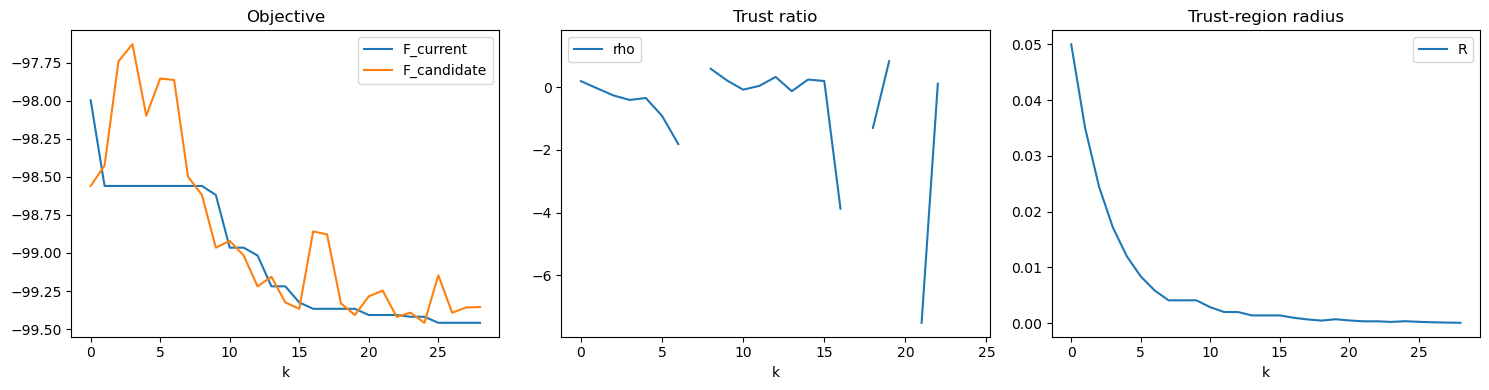

In [11]:
tr_prices = np.asarray(tr_result["x_opt"]).reshape(len(scenarios), T)
history = pd.DataFrame(tr_result["history"])
last_iteration = tr_result["history"][-1]
tr_objective = (
    last_iteration["F_current"]
    if last_iteration["decision"] == "reject"
    else last_iteration["F_candidate"]
)
tr_sampling_queries = tr_result["n_iter"] * (tr_config.algo_params["n_samples"] + 1)

comparison = pd.DataFrame(
    [
        {
            "method": "NN solver",
            "true_objective": nn_result["true_obj"],
            "runtime_seconds": nn_result["runtime_seconds"],
            "composite_queries": np.nan,
            "individual_follower_solves": np.nan,
        },
        {
            "method": "CMA-ES",
            "true_objective": zero_result["optimal value"],
            "runtime_seconds": zero_result["runtime_seconds"],
            "composite_queries": zero_result["n_interactions"],
            "individual_follower_solves": zero_result["n_interactions"] * len(scenarios),
        },
        {
            "method": "Trust region",
            "true_objective": tr_objective,
            "runtime_seconds": tr_result["elapsed_seconds"],
            "composite_queries": tr_sampling_queries,
            "individual_follower_solves": tr_sampling_queries * len(scenarios),
        },
    ]
).set_index("method")

print("Trust region converged:", tr_result["converged"])
print("Trust region iterations:", tr_result["n_iter"])
print("Saved paths:", tr_result.get("saved_paths"))
display(comparison)
display(pd.concat(
    {
        "NN solver": pd.DataFrame(nn_prices, index=scenarios),
        "CMA-ES": pd.DataFrame(zero_prices, index=scenarios),
        "Trust region": pd.DataFrame(tr_prices, index=scenarios),
    },
    names=["method", "scenario"],
))
display(history[[
    "k", "F_current", "F_candidate", "rho", "decision", "R",
    "max_rbf_condition", "geometry_resample_attempts",
]].tail())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
history.plot(x="k", y=["F_current", "F_candidate"], ax=axes[0], title="Objective")
history.plot(x="k", y="rho", ax=axes[1], title="Trust ratio")
history.plot(x="k", y="R", ax=axes[2], title="Trust-region radius")
plt.tight_layout()

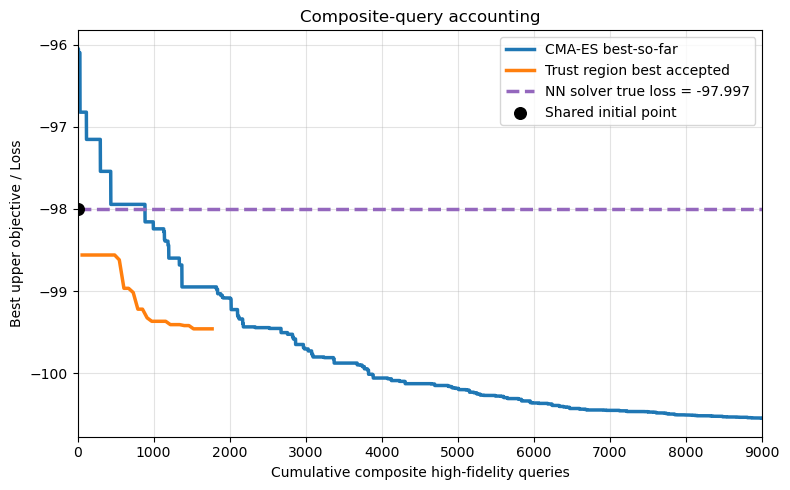

Saved figure to: /Users/liqi/Library/CloudStorage/OneDrive-TheUniversityofHongKong-Connect/Stackelberg Game/Surrogated-assisted Stackelnerg Game/plots/Cold_start_query_accounting42.pdf


In [12]:
# Compare methods using composite high-fidelity query accounting.
# CMA-ES n_interactions is the number of composite full-price queries.
zero_plot_df = zero_result["interaction_history"].copy()
zero_plot_df = zero_plot_df.sort_values("interaction").reset_index(drop=True)

tr_plot_df = history.copy()
tr_plot_df["accepted"] = tr_plot_df["decision"].str.startswith("accept")
tr_plot_df["cumulative_composite_queries"] = (
    (tr_plot_df["k"] + 1) * (tr_config.algo_params["n_samples"] + 1)
)

# Use the NN true loss as the query-zero incumbent for both warm-started methods.
# Any worse CMA-ES/TR objective is clipped to this baseline in the plot.
nn_true_loss = float(nn_result["true_obj"])
common_initial_objective = nn_true_loss

zero_plot_df = pd.concat(
    [
        # pd.DataFrame(
        #     {
        #         "interaction": [0],
        #         "upper_objective": [common_initial_objective],
        #     }
        # ),
        zero_plot_df[["interaction", "upper_objective"]],
    ],
    ignore_index=True,
)
# zero_plot_df["best_so_far_loss"] = np.minimum(
#     zero_plot_df["upper_objective"].cummin(),
#     nn_true_loss,
# )
zero_plot_df["best_so_far_loss"] = zero_plot_df["upper_objective"].cummin()

best_accepted = common_initial_objective
tr_best_values = []
for _, row in tr_plot_df.iterrows():
    if row["accepted"]:
        best_accepted = min(best_accepted, float(row["F_candidate"]))
    tr_best_values.append(best_accepted)
# tr_plot_df["best_true_objective"] = np.minimum(
#     tr_best_values,
#     nn_true_loss,
# )
tr_plot_df["best_true_objective"] = tr_best_values

tr_plot_df = pd.concat(
    [
        # pd.DataFrame(
        #     {
        #         "cumulative_composite_queries": [0],
        #         "best_true_objective": [common_initial_objective],
        #     }
        # ),
        tr_plot_df[[
            "cumulative_composite_queries",
            "best_true_objective",
        ]],
    ],
    ignore_index=True,
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    zero_plot_df["interaction"],
    zero_plot_df["best_so_far_loss"],
    linewidth=2.5,
    label="CMA-ES best-so-far",
)
ax.plot(
    tr_plot_df["cumulative_composite_queries"],
    tr_plot_df["best_true_objective"],
    linewidth=2.5,
    label="Trust region best accepted",
)
ax.axhline(
    nn_true_loss,
    color="tab:purple",
    linestyle="--",
    linewidth=2.5,
    label=f"NN solver true loss = {nn_true_loss:.3f}",
)
ax.scatter(
    [0],
    [common_initial_objective],
    color="black",
    s=70,
    zorder=5,
    label="Shared initial point",
)
x_max = max(
    int(zero_plot_df["interaction"].max()),
    int(tr_plot_df["cumulative_composite_queries"].max()),
)
ax.set_xlim(0, x_max)
ax.set_xlabel("Cumulative composite high-fidelity queries")
ax.set_ylabel("Best upper objective / Loss")
ax.set_title("Composite-query accounting")
ax.grid(alpha=0.35)
ax.legend()

fig.tight_layout()
plt.show()

output_path = Path("plots/Cold_start_query_accounting42.pdf")
output_path.parent.mkdir(parents=True, exist_ok=True)

fig.tight_layout()
fig.savefig(
    output_path,
    format="pdf",
    bbox_inches="tight",
)
plt.show()

print(f"Saved figure to: {output_path.resolve()}")